# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

Welcome to the Satellite Orbit Explorer! We will build this educational two-body orbit propagator together in 8 stages:
1. **Setup**: Imports, constants, directories, and configurations.
2. **Load GP JSON**: Download and load General Perturbations (GP) satellite data.
3. **Parse Elements**: Parse Keplerian elements from SGP4 mean element formats.
4. **Time Window**: Define our propagation window.
5. **Propagate**: Compute the orbital path using a two-body Keplerian model.
6. **Orbit Summary**: Extract key orbital parameters (period, apoapsis, periapsis).
7. **Plots**: Visualize the ground track and 3D orbit.
8. **KML and Report**: Export the results to a Google Earth KML file and generate a final report.

In [2]:
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import requests

# Stage 1: Constants (km, km/s, UTC-aware dates)
MU_EARTH_KM3_S2 = 398600.4418
EARTH_RADIUS_KM = 6378.137

# Setup workspace directories
WORKSPACE_DIR = Path('/content/satellite_orbits')
IN_DIR = WORKSPACE_DIR / 'input'
OUT_DIR = WORKSPACE_DIR / 'output'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Configuration parameters
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = None  # Optional extension configuration

# Print configuration to confirm success
print("--- Stage 1: Setup Completed Successfully ---")
print(f"Workspace: {WORKSPACE_DIR}")
print(f"Input Dir: {IN_DIR}")
print(f"Output Dir: {OUT_DIR}")
print(f"Simulation Config: Step = {STEP_SECONDS}s, Duration = {DURATION_HOURS}h, Live Group = {LIVE_GROUP}")
print(f"Earth MU: {MU_EARTH_KM3_S2} km^3/s^2, Radius: {EARTH_RADIUS_KM} km")

--- Stage 1: Setup Completed Successfully ---
Workspace: /content/satellite_orbits
Input Dir: /content/satellite_orbits/input
Output Dir: /content/satellite_orbits/output
Simulation Config: Step = 5s, Duration = 24h, Live Group = None
Earth MU: 398600.4418 km^3/s^2, Radius: 6378.137 km


In [3]:
def extract_inputs():
    """Checks for required files in IN_DIR. If missing, waits for zip upload and extracts them."""
    required_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).exists() for f in required_files)

    if all_exist:
        print("All required input files already exist in IN_DIR.")
        return

    print("--- Action Required ---")
    print("Please drag your 'orbit_workshop_inputs.zip' file into the /content folder (Colab Files panel).")
    print("Waiting for file upload...")

    timeout = time.time() + 900  # 15 minutes timeout
    zip_path = None

    while time.time() < timeout:
        # Look for any file in /content matching 'orbit_workshop_inputs*.zip'
        matches = list(Path('/content').glob('orbit_workshop_inputs*.zip'))
        if matches:
            candidate = matches[0]
            if zipfile.is_zipfile(candidate):
                # Verify it has completed uploading by attempting to open it
                try:
                    with zipfile.ZipFile(candidate) as z:
                        # Test zip file integrity
                        z.testzip()
                    zip_path = candidate
                    break
                except Exception:
                    pass
        time.sleep(2)

    if not zip_path:
        raise TimeoutError("Failed to find a completed zip upload in /content within 15 minutes.")

    print(f"Found valid zip file: {zip_path.name}. Extracting files to {IN_DIR}...")
    with zipfile.ZipFile(zip_path, 'r') as ref:
        for name in ref.namelist():
            filename = Path(name).name
            if filename in required_files:
                target_path = IN_DIR / filename
                with open(target_path, "wb") as out_f:
                    out_f.write(ref.read(name))
                print(f"Extracted: {filename}")

def read_gp_json(path):
    """Loads GP data from JSON and validates required OMM fields."""
    if not path.exists():
        raise FileNotFoundError(f"Required file {path} is missing. Complete prior steps first.")

    with open(path, 'r') as f:
        data = json.load(f)

    required_fields = [
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    ]

    for idx, record in enumerate(data):
        missing = [field for field in required_fields if field not in record]
        if missing:
            raise ValueError(f"Record at index {idx} ({record.get('OBJECT_NAME', 'Unknown')}) is missing fields: {missing}")

    return data

In [5]:
# Execute Stage 2 data loading
extract_inputs()

sats = read_gp_json(IN_DIR / 'orbital_elements.json')

# Load manifest to fetch metadata info
with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

source_note = f"Data source retrieved on UTC: {data_manifest['retrieved_utc']}"
print(f"\n{source_note}")
print(f"Successfully parsed {len(sats)} satellites:\n")
for sat in sats:
    print(f"Name: {sat['OBJECT_NAME']:<20} | NORAD ID: {sat['NORAD_CAT_ID']:<6} | Epoch: {sat['EPOCH']}")

--- Action Required ---
Please drag your 'orbit_workshop_inputs.zip' file into the /content folder (Colab Files panel).
Waiting for file upload...
Found valid zip file: orbit_workshop_inputs.zip. Extracting files to /content/satellite_orbits/input...
Extracted: orbital_elements.json
Extracted: data_manifest.json
Extracted: world_map.txt

Data source retrieved on UTC: 2026-11-10T16:30:32Z
Successfully parsed 4 satellites:

Name: PULSAR-0             | NORAD ID: 64541  | Epoch: 2026-11-10T04:10:34.900320
Name: GSAT0225 (GALILEO 29) | NORAD ID: 59598  | Epoch: 2026-11-09T08:30:06.579648
Name: SES-5                | NORAD ID: 38652  | Epoch: 2026-11-10T04:02:09.139776
Name: QZS-2 (MICHIBIKI-2)  | NORAD ID: 42738  | Epoch: 2026-10-17T15:21:52.982784


In [26]:
# --- Optional Extension: Live CelesTrak Data Stream ---
if LIVE_GROUP is None:
    print("Using offline workshop dataset snapshot. Live group retrieval is disabled.")
else:
    cache_path = IN_DIR / f'gp_{LIVE_GROUP}.json'
    use_cache = False

    if cache_path.exists():
        mtime = cache_path.stat().st_mtime
        age_hours = (time.time() - mtime) / 3600.0
        if age_hours < 2.0:
            use_cache = True
            print(f"Loading cached live data from {cache_path.name} (Age: {age_hours:.2f} hours)")

    if not use_cache:
        url = f'https://celestrak.org/NORAD/elements/gp.php?GROUP={LIVE_GROUP}&FORMAT=JSON'
        print(f"Fetching live element data from CelesTrak: {url}")
        try:
            resp = requests.get(url, timeout=30)
            resp.raise_for_status()
            live_data = resp.json()
            if not isinstance(live_data, list) or len(live_data) == 0:
                raise ValueError("Invalid or empty response format received from CelesTrak.")

            with open(cache_path, 'w', encoding='utf-8') as f:
                json.dump(live_data, f, indent=2)
            print(f"Successfully retrieved and cached {len(live_data)} elements to {cache_path.name}")
        except Exception as e:
            if cache_path.exists():
                print(f"Request failed ({e}). Falling back to expired cache.")
                with open(cache_path, 'r', encoding='utf-8') as f:
                    live_data = json.load(f)
            else:
                raise e
    else:
        with open(cache_path, 'r', encoding='utf-8') as f:
            live_data = json.load(f)

    # Sort live entries by NORAD_CAT_ID and select the first four
    sorted_sats = sorted(live_data, key=lambda x: int(x.get('NORAD_CAT_ID', 999999)))
    sats = sorted_sats[:4]

    retrieval_time = datetime.fromtimestamp(cache_path.stat().st_mtime, tz=timezone.utc).isoformat()
    source_note = f"Live data retrieved from CelesTrak (Group: {LIVE_GROUP}) on UTC: {retrieval_time}"

    print(f"\n{source_note}")
    print(f"Successfully selected {len(sats)} satellites from live group '{LIVE_GROUP}':\n")
    for sat in sats:
        print(f"Name: {sat['OBJECT_NAME']:<20} | NORAD ID: {sat['NORAD_CAT_ID']:<6} | Epoch: {sat['EPOCH']}")

Using offline workshop dataset snapshot. Live group retrieval is disabled.


### Why OMM JSON is Easier than Legacy TLE Formats

OMM (Orbit Mean-Elements Message) JSON format is significantly easier to use because it replaces cryptic, space-delimited text lines with clearly labeled, key-value pairs representing astronomical parameters directly. Additionally, it natively uses standardized ISO 8601 date strings for timestamps instead of custom Julian day decimals, and supports larger, six-digit catalog numbers without breaking positional column structures.

In [6]:
def parse_gp_epoch(text):
    """Parses ISO date string from CelesTrak into a UTC-aware datetime."""
    # Strip Z if present, append timezone info explicitly
    clean_text = text.rstrip('Z')
    return datetime.fromisoformat(clean_text).replace(tzinfo=timezone.utc)

def parse_gp_elements(rec):
    """Converts raw GP fields into physical Keplerian units (km, rad, rad/s)."""
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Mean motion: rev/day -> rad/s
    mean_motion_rev_day = float(rec['MEAN_MOTION'])
    n_rad_s = (mean_motion_rev_day * 2.0 * math.pi) / 86400.0

    # Semi-major axis (a) from Kepler's Third Law: n^2 * a^3 = MU
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1/3.0)

    # ECCENTRICITY is already parsed as a decimal float in OMM JSON
    e = float(rec['ECCENTRICITY'])

    # Convert angles from degrees to radians
    i_rad = math.radians(float(rec['INCLINATION']))
    raan_rad = math.radians(float(rec['RA_OF_ASC_NODE']))
    argp_rad = math.radians(float(rec['ARG_OF_PERICENTER']))
    M0_rad = math.radians(float(rec['MEAN_ANOMALY']))

    return {
        'name': name,
        'norad_id': norad_id,
        'label': f"{name} [{norad_id}]",
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': e,
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }

def elements_table(elements_list):
    """Generates a formatted text table of Keplerian elements."""
    lines = []
    header = f"{'Satellite Name':<20} | {'NORAD':<6} | {'Epoch (UTC)':<24} | {'a (km)':<10} | {'e':<8} | {'i (°)':<6} | {'Ω (°)':<6} | {'ω (°)':<6} | {'M (°)'}"
    separator = "-" * len(header)
    lines.append(header)
    lines.append(separator)

    for el in elements_list:
        lines.append(
            f"{el['name']:<20} | "
            f"{el['norad_id']:<6} | "
            f"{el['epoch'].strftime('%Y-%m-%d %H:%M:%S'):<24} | "
            f"{el['a_km']:10.2f} | "
            f"{el['e']:8.6f} | "
            f"{math.degrees(el['i_rad']):6.2f} | "
            f"{math.degrees(el['raan_rad']):6.2f} | "
            f"{math.degrees(el['argp_rad']):6.2f} | "
            f"{math.degrees(el['M0_rad']):6.2f}"
        )
    return lines

In [7]:
# Validate and parse all loaded satellites
if 'sats' not in globals():
    raise NameError("Missing 'sats' from Stage 2. Please make sure Stage 2 executed successfully.")

elements = [parse_gp_elements(s) for s in sats]

# Generate and print the elements table
table_lines = elements_table(elements)
for line in table_lines:
    print(line)

Satellite Name       | NORAD  | Epoch (UTC)              | a (km)     | e        | i (°)  | Ω (°)  | ω (°)  | M (°)
-------------------------------------------------------------------------------------------------------------------
PULSAR-0             | 64541  | 2026-11-10 04:10:34      |    6880.97 | 0.000408 |  97.48 |  67.63 |  54.16 | 306.00
GSAT0225 (GALILEO 29) | 59598  | 2026-11-09 08:30:06      |   29600.26 | 0.000159 |  55.22 |  97.02 | 171.21 | 226.89
SES-5                | 38652  | 2026-11-10 04:02:09      |   42164.28 | 0.000191 |   0.05 |  32.20 | 188.01 | 254.68
QZS-2 (MICHIBIKI-2)  | 42738  | 2026-10-17 15:21:52      |   42170.36 | 0.074521 |  39.25 | 241.35 | 270.89 | 243.82


### Element Parsing and Approximations

| GP JSON Field | Physical Symbol | Meaning | Unit Conversion / Derivation |
| :--- | :---: | :--- | :--- |
| `MEAN_MOTION` | $n$ | Mean Motion | $\text{rev/day} \rightarrow \text{rad/s}$ via $\frac{2\pi}{86400}$ |
| *Derived (Kepler 3)* | $a$ | Semi-major axis | $a = \left(\frac{\mu_{Earth}}{n^2}\right)^{1/3}$ in $\text{km}$ |
| `ECCENTRICITY` | $e$ | Eccentricity | Dimensionless decimal fraction |
| `INCLINATION` | $i$ | Inclination | $\text{degrees} \rightarrow \text{radians}$ |
| `RA_OF_ASC_NODE` | $\Omega$ | Right Ascension of Ascending Node | $\text{degrees} \rightarrow \text{radians}$ |
| `ARG_OF_PERICENTER` | $\omega$ | Argument of Perigee | $\text{degrees} \rightarrow \text{radians}$ |
| `MEAN_ANOMALY` | $M_0$ | Mean Anomaly at Epoch | $\text{degrees} \rightarrow \text{radians}$ |

> **Note on Accuracy**: General Perturbation (GP) parameters represent SGP4 mean elements, which are mathematically formulated to include average drag and geopotential perturbations. Applying them directly to a pure two-body Keplerian propagator is an educational approximation that will drift slightly from true positions, rather than a precision orbit prediction.

In [8]:
# Stage 4: Define a unified time grid based on the newest epoch
if 'elements' not in globals() or not elements:
    raise NameError("Missing 'elements' list from Stage 3. Please run previous stages first.")

# Find the newest epoch among all satellites
newest_epoch = max(el['epoch'] for el in elements)

# Floor the newest epoch to UTC midnight
sim_start = datetime.combine(newest_epoch.date(), datetime.min.time(), tzinfo=timezone.utc)
sim_end = sim_start + timedelta(hours=DURATION_HOURS)

# Calculate grid size (inclusive of start and end)
total_duration_seconds = int((sim_end - sim_start).total_seconds())
n_points = total_duration_seconds // STEP_SECONDS + 1

# Generate time grid
times = [sim_start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

print("--- Stage 4: Unified Time Grid ---")
print(f"Simulation Start (UTC): {sim_start}")
print(f"Simulation End (UTC)  : {sim_end}")
print(f"Step size (seconds)   : {STEP_SECONDS}")
print(f"Number of points      : {n_points}\n")

# Check for stale data based on the epoch offset
print("Satellite Epoch Offsets from Grid Start:")
for el in elements:
    # Offset in days
    offset_days = (sim_start - el['epoch']).total_seconds() / 86400.0
    stale_flag = "[STALE]" if abs(offset_days) > 7 else "[OK]"
    print(f"- {el['label']:<25} | Offset: {offset_days:6.2f} days | Status: {stale_flag}")

--- Stage 4: Unified Time Grid ---
Simulation Start (UTC): 2026-11-10 00:00:00+00:00
Simulation End (UTC)  : 2026-11-11 00:00:00+00:00
Step size (seconds)   : 5
Number of points      : 17281

Satellite Epoch Offsets from Grid Start:
- PULSAR-0 [64541]          | Offset:  -0.17 days | Status: [OK]
- GSAT0225 (GALILEO 29) [59598] | Offset:   0.65 days | Status: [OK]
- SES-5 [38652]             | Offset:  -0.17 days | Status: [OK]
- QZS-2 (MICHIBIKI-2) [42738] | Offset:  23.36 days | Status: [STALE]


### Why Epoch Alignment and Age Matter

Each satellite record's Keplerian parameters are snapshot estimates captured at its specific `EPOCH`. Because our simple two-body propagator ignores external gravitational perturbations, solar radiation pressure, and atmospheric drag, the prediction error grows progressively as we model further away from each satellite's original epoch. Tracking the offset in days helps us identify older data, such as our workshop's QZS-2 record (which dates back to 17 October 2026), that is highly prone to increased drift and propagation errors.

In [9]:
def solve_kepler(M, e, tol=1e-12, max_iter=50):
    """Solves Kepler's Equation: M = E - e*sin(E) using Newton-Raphson."""
    # 1. Choose a robust starting value for Eccentric Anomaly (E)
    E = math.pi if e > 0.8 else M
    for _ in range(max_iter):
        f = E - e * math.sin(E) - M
        f_prime = 1.0 - e * math.cos(E)
        delta = f / f_prime
        E -= delta
        if abs(delta) < tol:
            return E
    raise ValueError(f"Kepler solver failed to converge. M={M}, e={e}")

def gmst_rad(t):
    """Greenwich Mean Sidereal Time (GMST) IAU-1982 formula in radians."""
    # J2000 Epoch is January 1, 2000 at 12:00:00 UTC
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (t - j2000).total_seconds() / 86400.0
    T = d / 36525.0

    # IAU 1982 formulation for GMST in degrees
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2) - (T ** 3) / 38710000.0
    theta_rad = math.radians(theta_deg % 360.0)
    return theta_rad

def propagate(el, times_grid):
    """Propagates the satellite orbit over a given UTC time grid."""
    track = []
    epoch = el['epoch']
    n = el['n_rad_s']
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']

    for t in times_grid:
        dt_sec = (t - epoch).total_seconds()

        # Step 1: Mean Anomaly update
        M = (M0 + n * dt_sec) % (2.0 * math.pi)

        # Step 2: Eccentric Anomaly via Kepler Solver
        E = solve_kepler(M, e)

        # Step 3: Radial distance and True Anomaly (nu)
        r = a * (1.0 - e * math.cos(E))
        nu = math.atan2(math.sqrt(1.0 - e**2) * math.sin(E), math.cos(E) - e)
        u = argp + nu

        # Step 4: Geocentric Inertial Position (x, y, z)
        cos_u, sin_u = math.cos(u), math.sin(u)
        cos_raan, sin_raan = math.cos(raan), math.sin(raan)
        cos_i, sin_i = math.cos(i), math.sin(i)

        x = r * (cos_raan * cos_u - sin_raan * sin_u * cos_i)
        y = r * (sin_raan * cos_u + cos_raan * sin_u * cos_i)
        z = r * sin_u * sin_i

        # Step 5: Rotate into Earth-Centered Earth-Fixed (ECEF) coordinates using GMST
        theta = gmst_rad(t)
        cos_theta, sin_theta = math.cos(theta), math.sin(theta)
        x_ecef = cos_theta * x + sin_theta * y
        y_ecef = -sin_theta * x + cos_theta * y

        # Step 6: Convert to Latitude, Longitude, and Altitude
        lat_rad = math.atan2(z, math.hypot(x_ecef, y_ecef))
        lon_rad = math.atan2(y_ecef, x_ecef)

        lat_deg = math.degrees(lat_rad)
        # Keep longitude in [-180, 180]
        lon_deg = (math.degrees(lon_rad) + 180.0) % 360.0 - 180.0
        alt_km = r - EARTH_RADIUS_KM

        # Step 7: Vis-Viva Equation Speed
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        track.append({
            'time': t,
            'lat_deg': lat_deg,
            'lon_deg': lon_deg,
            'alt_km': alt_km,
            'speed_km_s': speed_km_s,
            'r_vector': (x_ecef, y_ecef, z) # for plotting and visual use later
        })
    return track

In [10]:
# Execute tests to verify solver accuracy and GMST alignment
j2000_epoch = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
gmst_j2000_deg = math.degrees(gmst_rad(j2000_epoch))
print(f"Verification: GMST at J2000 = {gmst_j2000_deg:.6f}° (Expected ~280.46°)")
assert abs(gmst_j2000_deg - 280.460618) < 1e-4, "GMST at J2000 verification failed!"

# Kepler Solver verification tests
for M_test, e_test in [(0.5, 0.1), (1.5, 0.5), (3.0, 0.05)]:
    E_res = solve_kepler(M_test, e_test)
    residual = abs(E_res - e_test * math.sin(E_res) - M_test)
    print(f"Kepler Residual (M={M_test}, e={e_test}): {residual:.2e}")
    assert residual < 1e-10, "Kepler solver failed verification!"

# Run propagation over our time grid
if 'elements' not in globals() or 'times' not in globals():
    raise NameError("Missing variables from previous stages. Ensure Stages 1-4 ran.")

tracks = [propagate(el, times) for el in elements]
print("\n--- Propagation Complete ---")

# Display first, middle, and last data points for each satellite
for idx, el in enumerate(elements):
    track = tracks[idx]
    n_pts = len(track)
    print(f"\n{el['label']} ({n_pts} points):")
    for pos, label in [(0, 'First'), (n_pts // 2, 'Middle'), (n_pts - 1, 'Last')]:
        pt = track[pos]
        print(f"  {label:<6} | {pt['time'].strftime('%H:%M:%S')} | Lat: {pt['lat_deg']:6.2f}° | Lon: {pt['lon_deg']:7.2f}° | Alt: {pt['alt_km']:7.1f} km | Speed: {pt['speed_km_s']:.3f} km/s")

# Geostationary drift assertion verification (SES-5) if present
ses5_track = next((t for t, el in zip(tracks, elements) if el['norad_id'] == 38652), None)
if ses5_track:
    lons = [pt['lon_deg'] for pt in ses5_track]
    min_lon, max_lon = min(lons), max(lons)
    print(f"\nSES-5 Longitude Bound Check: {min_lon:.2f}°E to {max_lon:.2f}°E")
    assert all(4.0 <= lon <= 6.0 for lon in lons), f"SES-5 drifted outside 4.0 - 6.0° E bounds (got {min_lon:.2f} to {max_lon:.2f}). Check GMST computation."
    print("SES-5 Geostationary longitude test PASSED!")

Verification: GMST at J2000 = 280.460618° (Expected ~280.46°)
Kepler Residual (M=0.5, e=0.1): 0.00e+00
Kepler Residual (M=1.5, e=0.5): 0.00e+00
Kepler Residual (M=3.0, e=0.05): 0.00e+00

--- Propagation Complete ---

PULSAR-0 [64541] (17281 points):
  First  | 00:00:00 | Lat:  51.99° | Lon: -151.86° | Alt:   502.0 km | Speed: 7.612 km/s
  Middle | 12:00:00 | Lat: -14.79° | Lon: -160.05° | Alt:   501.8 km | Speed: 7.612 km/s
  Last   | 00:00:00 | Lat: -22.73° | Lon: -165.68° | Alt:   505.2 km | Speed: 7.608 km/s

GSAT0225 (GALILEO 29) [59598] (17281 points):
  First  | 00:00:00 | Lat:  52.28° | Lon:  111.76° | Alt: 23222.7 km | Speed: 3.670 km/s
  Middle | 12:00:00 | Lat:  17.32° | Lon: -120.13° | Alt: 23226.2 km | Speed: 3.669 km/s
  Last   | 00:00:00 | Lat: -25.70° | Lon:   27.34° | Alt: 23226.4 km | Speed: 3.669 km/s

SES-5 [38652] (17281 points):
  First  | 00:00:00 | Lat:   0.02° | Lon:    5.00° | Alt: 35794.0 km | Speed: 3.074 km/s
  Middle | 12:00:00 | Lat:  -0.02° | Lon:    5.01

### Physics and Orbit Propagation Steps
Our simple orbital model computes positions on a spherical, rotating Earth:
1. **Mean Anomaly Progression ($M$)**: Updates linearly with time from the epoch initial angle $M_0$ at the rate of Mean Motion ($n$).
2. **Kepler's Equation**: Solved via Newton-Raphson iterations to yield the Eccentric Anomaly ($E$).
3. **True Anomaly ($\nu$) and Orbital Radius ($r$)**: Converts $E$ to polar orbital coordinates.
4. **Inertial ECI Axes ($x, y, z$)**: Evaluates orbital geometry using Inclination ($i$), RAAN ($\Omega$), and Argument of Perigee ($\omega$).
5. **Sidereal Rotation (ECEF $x', y', z'$)**: Rotates the inertial system into the rotating frame of the Earth using Greenwich Mean Sidereal Time (GMST) calculated via the IAU-1982 formulation.
6. **Geographic Coordinates (Lat, Lon, Alt)**: Project ECEF coordinates onto a spherical Earth surface model.
7. **Vis-Viva Speed**: Computes orbital velocity at any position $r$ along the Keplerian ellipse.

In [11]:
def orbit_summary(el, pts):
    """Calculates physical characteristics of the orbit and simulated speed bounds."""
    a = el['a_km']
    e = el['e']
    n = el['n_rad_s']

    # Analytical parameters
    period_h = (2.0 * math.pi / n) / 3600.0
    perigee_km = a * (1.0 - e) - EARTH_RADIUS_KM
    apogee_km = a * (1.0 + e) - EARTH_RADIUS_KM
    i_deg = math.degrees(el['i_rad'])

    # Simulated speed extremes from the track points
    speeds = [pt['speed_km_s'] for pt in pts]
    min_speed = min(speeds)
    max_speed = max(speeds)

    return {
        'name': el['name'],
        'norad_id': el['norad_id'],
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': i_deg,
        'min_speed': min_speed,
        'max_speed': max_speed
    }

def summary_table(summaries_list):
    """Generates a formatted text table of the orbital summaries."""
    lines = []
    header = f"{'Satellite Name':<20} | {'NORAD':<6} | {'Period (h)':<10} | {'Perigee (km)':<12} | {'Apogee (km)':<12} | {'e':<8} | {'i (°)':<6} | {'Min V (km/s)':<12} | {'Max V (km/s)'}"
    separator = "-" * len(header)
    lines.append(header)
    lines.append(separator)

    for s in summaries_list:
        lines.append(
            f"{s['name']:<20} | "
            f"{s['norad_id']:<6} | "
            f"{s['period_h']:10.2f} | "
            f"{s['perigee_km']:12.1f} | "
            f"{s['apogee_km']:12.1f} | "
            f"{s['e']:8.6f} | "
            f"{s['i_deg']:6.2f} | "
            f"{s['min_speed']:12.3f} | "
            f"{s['max_speed']:11.3f}"
        )
    return lines

In [12]:
# Validate inputs exist from Stage 3 and Stage 5
if 'elements' not in globals() or 'tracks' not in globals():
    raise NameError("Missing 'elements' or 'tracks' from earlier stages. Ensure Stages 1-5 ran.")

# Compute summaries for all satellites
summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

# Generate and print the orbital summaries table
summary_lines = summary_table(summaries)
print("--- Stage 6: Orbit Summary Table ---")
for line in summary_lines:
    print(line)

# Check for Galileo 29 (NORAD 59598) and verify its orbital period
galileo29 = next((s for s in summaries if s['norad_id'] == 59598), None)
if galileo29:
    p_hours = galileo29['period_h']
    print(f"\nGalileo 29 Orbital Period: {p_hours:.4f} h")
    assert 14.0 <= p_hours <= 14.2, f"Galileo 29 period ({p_hours:.4f} h) is outside [14.0, 14.2] h!"
    print("Galileo 29 orbital period validation PASSED!")

--- Stage 6: Orbit Summary Table ---
Satellite Name       | NORAD  | Period (h) | Perigee (km) | Apogee (km)  | e        | i (°)  | Min V (km/s) | Max V (km/s)
--------------------------------------------------------------------------------------------------------------------------
PULSAR-0             | 64541  |       1.58 |        500.0 |        505.6 | 0.000408 |  97.48 |        7.608 |       7.614
GSAT0225 (GALILEO 29) | 59598  |      14.08 |      23217.4 |      23226.8 | 0.000159 |  55.22 |        3.669 |       3.670
SES-5                | 38652  |      23.93 |      35778.1 |      35794.2 | 0.000191 |   0.05 |        3.074 |       3.075
QZS-2 (MICHIBIKI-2)  | 42738  |      23.94 |      32649.6 |      38934.8 | 0.074521 |  39.25 |        2.853 |       3.313

Galileo 29 Orbital Period: 14.0783 h
Galileo 29 orbital period validation PASSED!


### Interpretation of Orbital Values

Looking at the computed parameters, we can clearly distinguish the different orbital regimes of the satellites:

*   **PULSAR-0**: With a short period of approximately **1.58 hours** and an inclination around **97.5 degrees**, this satellite operates in a retrograde, near-polar, Sun-Synchronous Low Earth Orbit (LEO).
*   **Galileo 29**: Exhibits a semi-synchronous Medium Earth Orbit (MEO) with a period of **14.08 hours**, typical of global navigation satellite systems.
*   **SES-5 & QZS-2**: Both share an orbital period of approximately **23.93 hours** (one sidereal day, matching Earth's rotation).
    *   **SES-5** has a near-zero eccentricity and inclination, making it a classic Geostationary Orbit (GEO) satellite parked at a constant longitude.
    *   **QZS-2**, however, features an eccentricity of roughly **0.07** and an inclination of around **39 degrees**. This configuration forms an Inclined Geosynchronous Orbit (IGSO) rather than a geostationary one, tracing an asymmetric figure-eight (analemma) over Japan and Australia.

In [13]:
def load_coastline(path):
    """Parses world_map.txt with 'latitude longitude' pairs separated by blanks into segments."""
    if not path.exists():
        raise FileNotFoundError(f"Missing world_map.txt at: {path}")

    segments = []
    current_segment = []

    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = line.split()
                if len(parts) == 2:
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_segment.append((lon, lat))

        if current_segment:
            segments.append(current_segment)

    return segments

# Consistent color palette mapped to our satellites
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

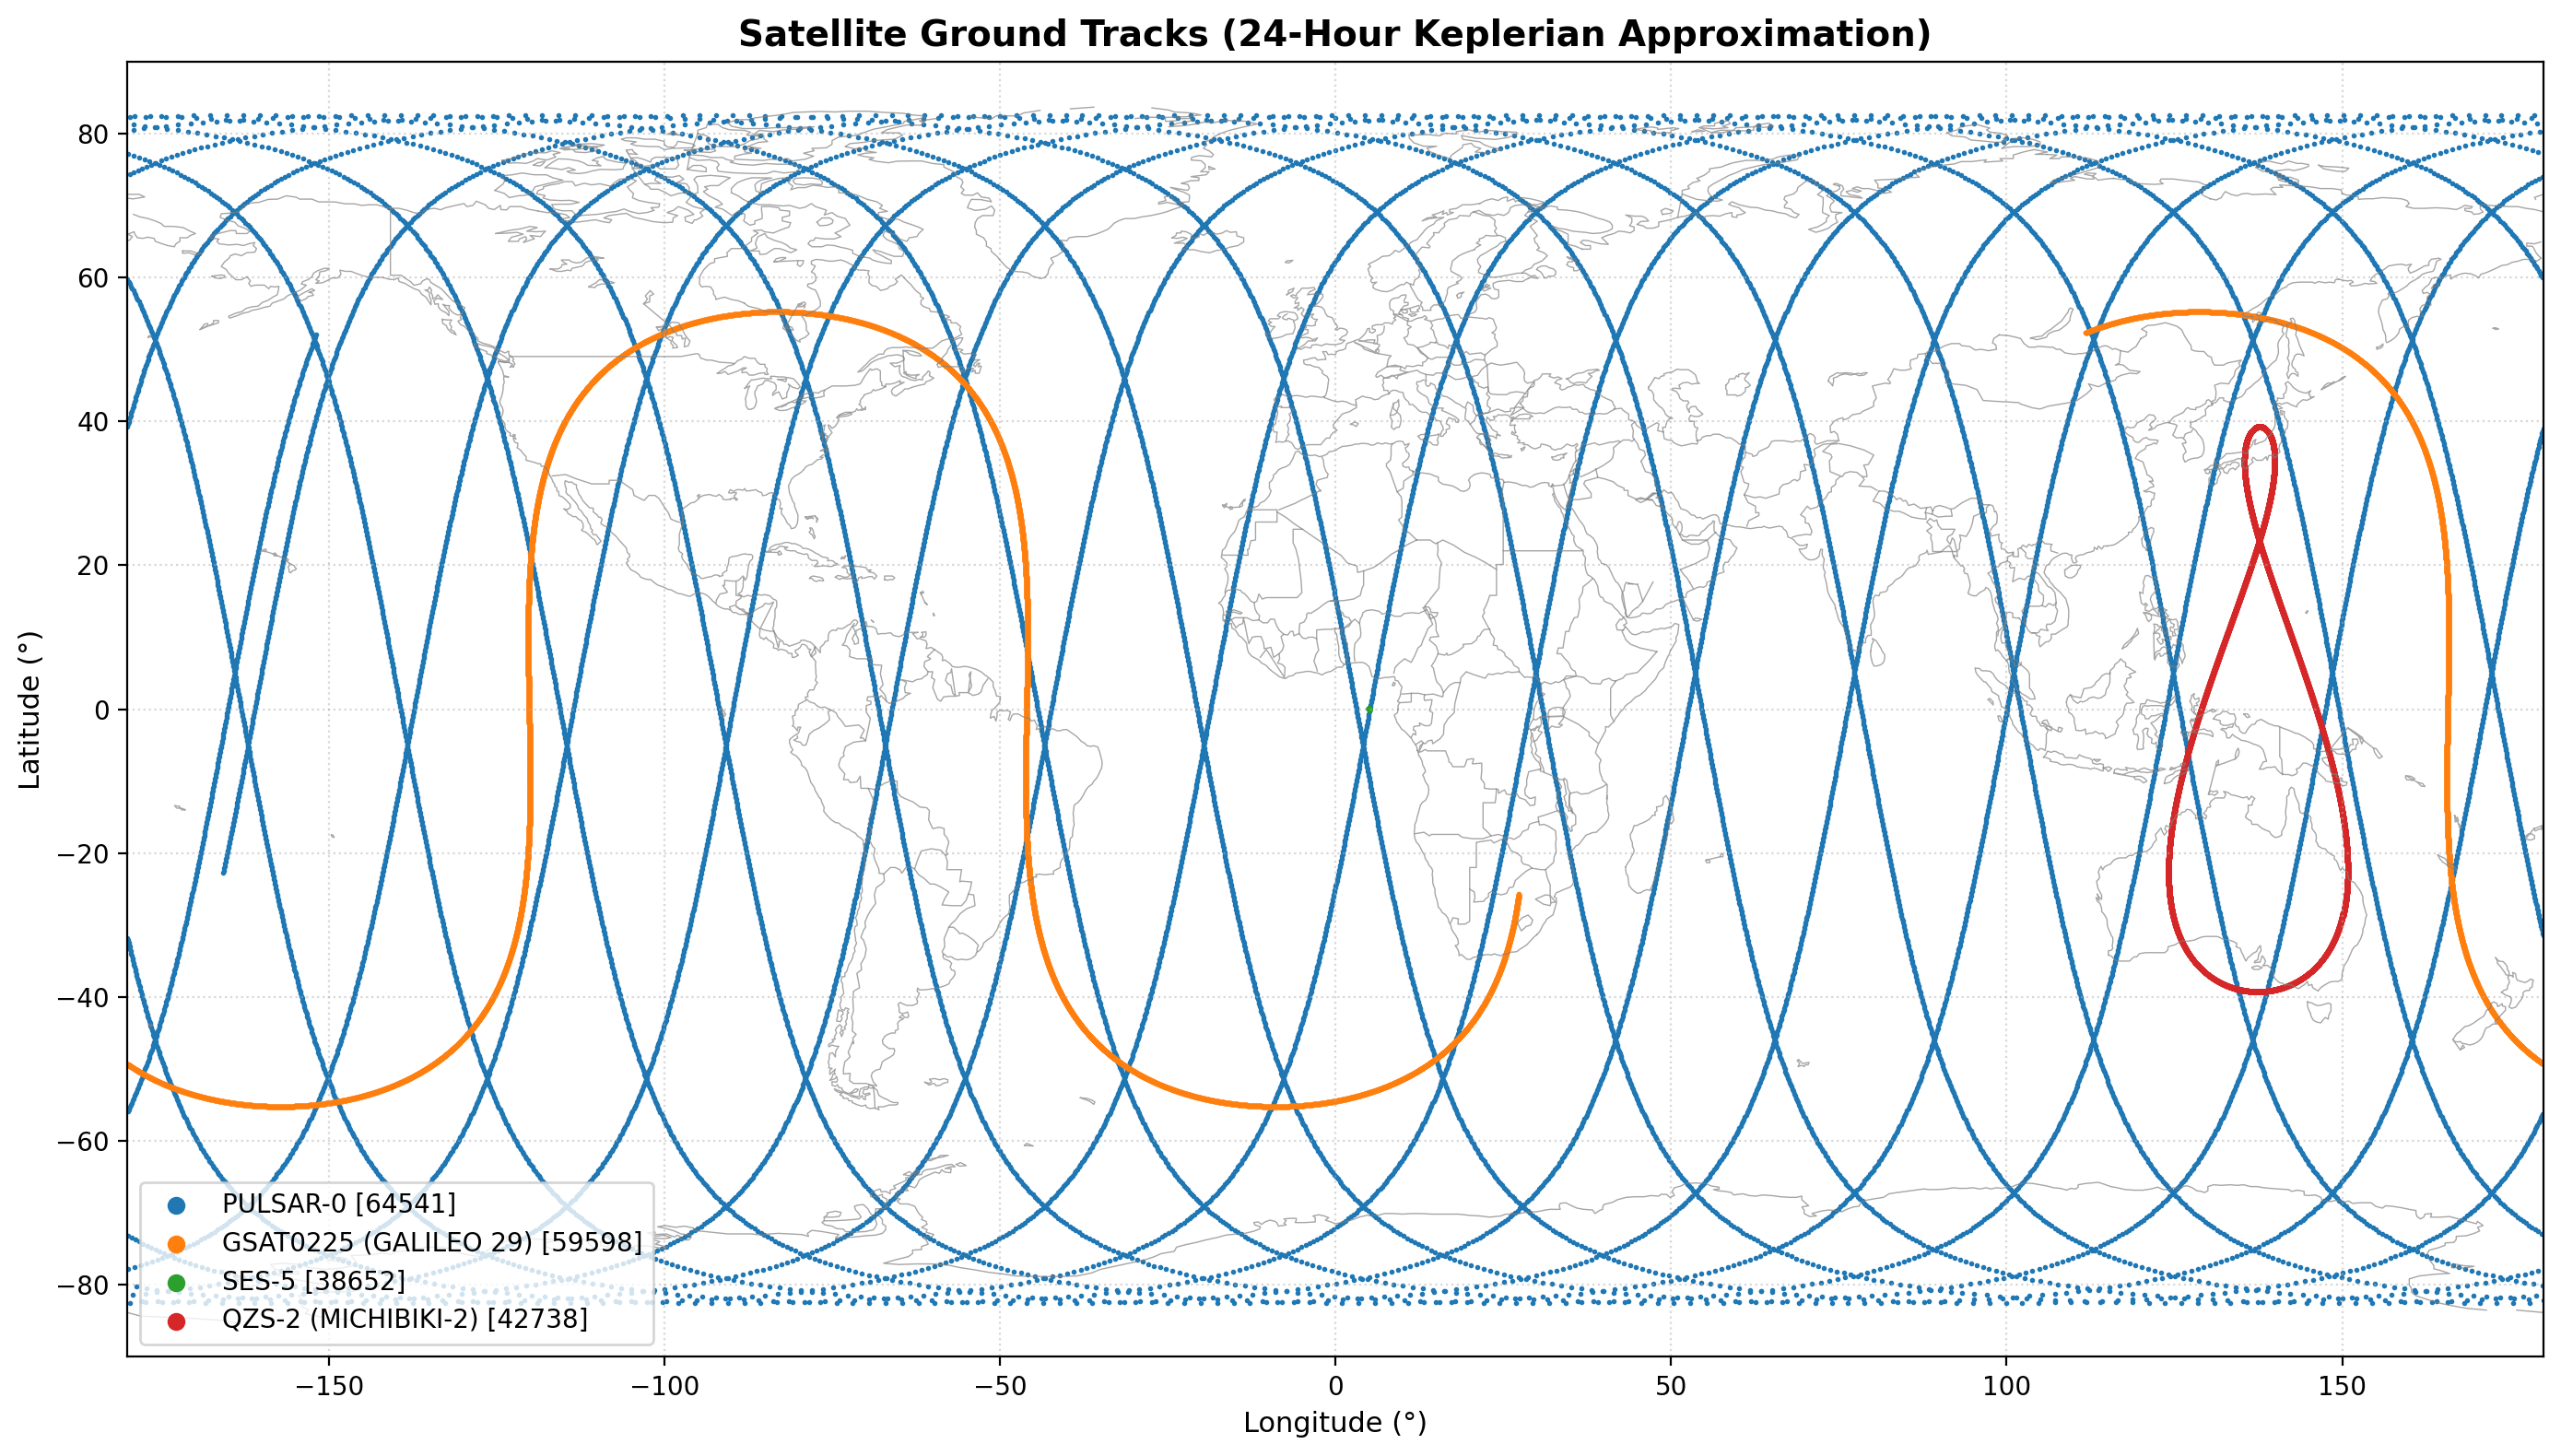

Saved ground tracks plot to /content/satellite_orbits/output/ground_tracks.png


In [14]:
if 'elements' not in globals() or 'tracks' not in globals():
    raise NameError("Missing 'elements' or 'tracks' from earlier stages. Ensure Stages 1-6 ran.")

# Load world coastline segments
coast_segments = load_coastline(IN_DIR / 'world_map.txt')

# --- Figure 1: Ground Tracks Plot ---
plt.figure(figsize=(14, 8), dpi=200)

# Draw coastlines
for seg in coast_segments:
    lon_val, lat_val = zip(*seg)
    plt.plot(lon_val, lat_val, color='gray', linewidth=0.5, alpha=0.7)

# Plot satellite ground tracks as scatters to avoid false cross-world wrapping lines
for idx, el in enumerate(elements):
    track = tracks[idx]
    lons = [pt['lon_deg'] for pt in track]
    lats = [pt['lat_deg'] for pt in track]

    plt.scatter(
        lons, lats,
        color=COLORS[idx % len(COLORS)],
        s=1,
        label=el['label']
    )

plt.title("Satellite Ground Tracks (24-Hour Keplerian Approximation)", fontsize=14, fontweight='bold')
plt.xlabel("Longitude (°)", fontsize=11)
plt.ylabel("Latitude (°)", fontsize=11)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(markerscale=6, loc='lower left')
plt.tight_layout()

ground_tracks_path = OUT_DIR / 'ground_tracks.png'
plt.savefig(ground_tracks_path, dpi=200)
plt.show()
print(f"Saved ground tracks plot to {ground_tracks_path}")

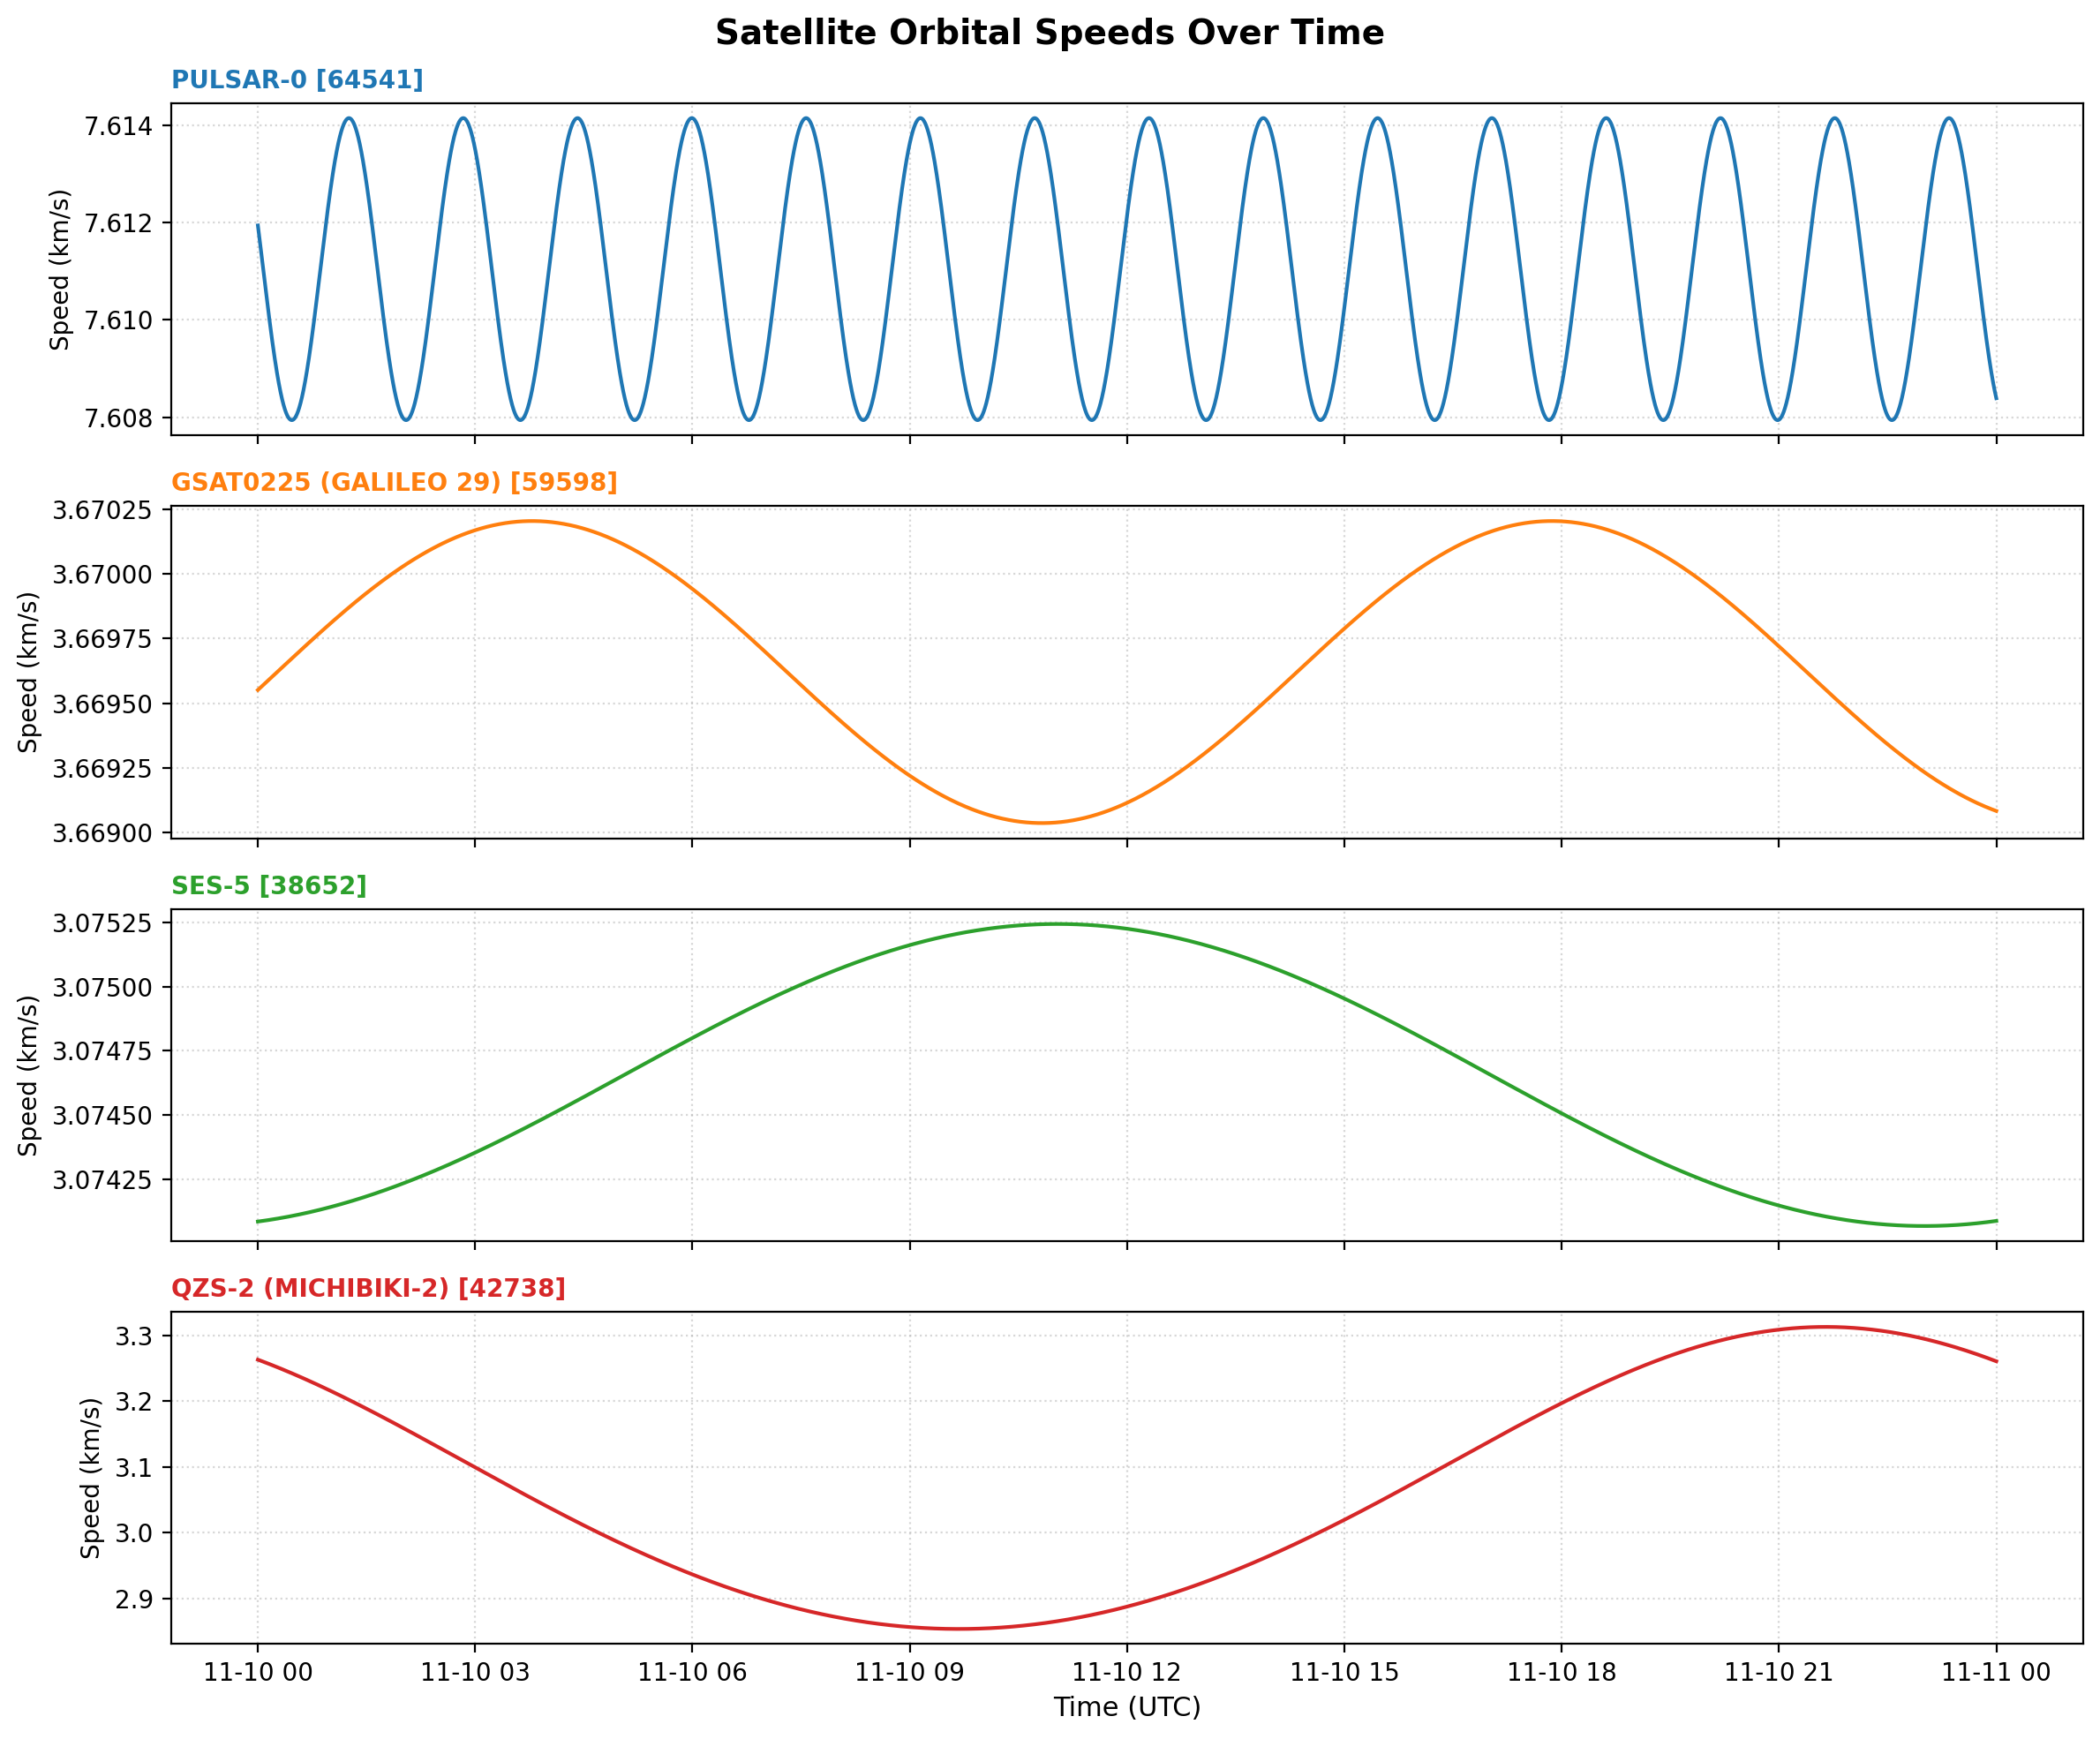

Saved velocity timeseries plot to /content/satellite_orbits/output/velocity_timeseries.png


In [15]:
# --- Figure 2: Velocity Timeseries Plot ---
fig, axs = plt.subplots(len(elements), 1, figsize=(12, 10), sharex=True, dpi=200)
if len(elements) == 1:
    axs = [axs]

for idx, el in enumerate(elements):
    track = tracks[idx]
    times_list = [pt['time'] for pt in track]
    speeds = [pt['speed_km_s'] for pt in track]
    col = COLORS[idx % len(COLORS)]

    axs[idx].plot(times_list, speeds, color=col, linewidth=1.5)
    axs[idx].set_ylabel("Speed (km/s)", fontsize=10)
    axs[idx].grid(True, linestyle=':', alpha=0.5)
    axs[idx].get_yaxis().get_major_formatter().set_useOffset(False)  # Turn off offset notation
    axs[idx].set_title(el['label'], fontsize=10, loc='left', color=col, fontweight='bold')

axs[-1].set_xlabel("Time (UTC)", fontsize=11)
plt.suptitle("Satellite Orbital Speeds Over Time", fontsize=14, fontweight='bold')
plt.tight_layout()

velocity_path = OUT_DIR / 'velocity_timeseries.png'
plt.savefig(velocity_path, dpi=200)
plt.show()
print(f"Saved velocity timeseries plot to {velocity_path}")

In [16]:
def generate_kml(elements_list, tracks_list, colors_list, path):
    """Generates a standard Google Earth KML file for all satellite ground tracks."""
    # Create root KML element with correct XML structure and namespaces
    kml = ET.Element("kml", xmlns="http://www.opengis.net/kml/2.2")
    document = ET.SubElement(kml, "Document")

    name_elem = ET.SubElement(document, "name")
    name_elem.text = "Satellite Orbit Explorer Tracks"

    # Generate styles for color-coded paths
    for idx, el in enumerate(elements_list):
        col_hex = mcolors.to_hex(colors_list[idx % len(colors_list)]).replace('#', '')
        # KML color format is aabbggrr (alpha, blue, green, red)
        kml_color = f"ff{col_hex[4:6]}{col_hex[2:4]}{col_hex[0:2]}"

        style = ET.SubElement(document, "Style", id=f"style_{el['norad_id']}")
        linestyle = ET.SubElement(style, "LineStyle")
        col_node = ET.SubElement(linestyle, "color")
        col_node.text = kml_color
        width = ET.SubElement(linestyle, "width")
        width.text = "2"

    # Create geographic track Placemarks
    for idx, el in enumerate(elements_list):
        track = tracks_list[idx]
        placemark = ET.SubElement(document, "Placemark")

        p_name = ET.SubElement(placemark, "name")
        p_name.text = el['name']

        p_desc = ET.SubElement(placemark, "description")
        p_desc.text = f"NORAD ID: {el['norad_id']}\nOrbit Period: {2.0 * math.pi / el['n_rad_s'] / 3600.0:.2f} h"

        style_url = ET.SubElement(placemark, "styleUrl")
        style_url.text = f"#style_{el['norad_id']}"

        line = ET.SubElement(placemark, "LineString")
        extrude = ET.SubElement(line, "extrude")
        extrude.text = "0"
        tessellate = ET.SubElement(line, "tessellate")
        tessellate.text = "1"
        altitude_mode = ET.SubElement(line, "altitudeMode")
        altitude_mode.text = "clampToGround"

        coords = ET.SubElement(line, "coordinates")

        # Build the coordinate coordinate string: "lon,lat,alt lon,lat,alt ..."
        coord_parts = []
        for pt in track:
            coord_parts.append(f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},0")
        coords.text = " ".join(coord_parts)

    # Write formatted XML tree to file
    tree = ET.ElementTree(kml)
    ET.indent(tree, space="  ", level=0)
    tree.write(path, encoding="utf-8", xml_declaration=True)
    print(f"Successfully generated KML file: {path.name}")

In [17]:
# Validate prior elements exist
if 'elements' not in globals() or 'tracks' not in globals() or 'summaries' not in globals():
    raise NameError("Missing prerequisite orbital data from previous steps. Complete Stages 1-7.")

kml_output_path = OUT_DIR / 'orbit_explorer_tracks.kml'
generate_kml(elements, tracks, COLORS, kml_output_path)

# --- Create Final Markdown/ASCII Report ---
report_lines = []
report_lines.append("===================================================================")
report_lines.append("   SATELLITE ORBIT EXPLORER FINAL SUMMARY REPORT (2-BODY APPROX)")
report_lines.append("===================================================================")
report_lines.append(f"Generated on (UTC): {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S')}")
report_lines.append(source_note if 'source_note' in globals() else "")
report_lines.append(f"Simulation Period : {sim_start} to {sim_end}")
report_lines.append(f"Time Step Size    : {STEP_SECONDS} seconds | Steps count: {n_points}")
report_lines.append("\n1. INPUT KEPLERIAN ELEMENTS AT DATASETS EPOCH:")
report_lines.extend(elements_table(elements))
report_lines.append("\n2. PROPAGATED ORBITS DYNAMIC SUMMARY:")
report_lines.extend(summary_table(summaries))
report_lines.append("\n======================= END OF REPORT =============================")

report_text = "\n".join(report_lines)
report_path = OUT_DIR / 'final_report.txt'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write(report_text)

print(f"\nSaved final report to {report_path.name}\n")
print(report_text)

Successfully generated KML file: orbit_explorer_tracks.kml

Saved final report to final_report.txt

   SATELLITE ORBIT EXPLORER FINAL SUMMARY REPORT (2-BODY APPROX)
Generated on (UTC): 2026-11-11 20:42:11
Data source retrieved on UTC: 2026-11-10T16:30:32Z
Simulation Period : 2026-11-10 00:00:00+00:00 to 2026-11-11 00:00:00+00:00
Time Step Size    : 5 seconds | Steps count: 17281

1. INPUT KEPLERIAN ELEMENTS AT DATASETS EPOCH:
Satellite Name       | NORAD  | Epoch (UTC)              | a (km)     | e        | i (°)  | Ω (°)  | ω (°)  | M (°)
-------------------------------------------------------------------------------------------------------------------
PULSAR-0             | 64541  | 2026-11-10 04:10:34      |    6880.97 | 0.000408 |  97.48 |  67.63 |  54.16 | 306.00
GSAT0225 (GALILEO 29) | 59598  | 2026-11-09 08:30:06      |   29600.26 | 0.000159 |  55.22 |  97.02 | 171.21 | 226.89
SES-5                | 38652  | 2026-11-10 04:02:09      |   42164.28 | 0.000191 |   0.05 |  32.20 | 18

### Final Export and Review

We have successfully completed the 8th and final stage of our **Satellite Orbit Explorer**!

1.  **Google Earth KML Export**: The file `orbit_explorer_tracks.kml` was successfully created inside `/content/satellite_orbits/output/`. Each satellite path is exported as a continuous geographic LineString using the same color-coding established during plotting to ensure clean, consistent data visualization.
2.  **Summary Report**: The complete dynamic report (`final_report.txt`) compiles elements parsing from Stage 3 alongside our simulated velocity extremes and geometric ranges from Stage 6.

With both reports written to the workspace, you can easily download these outputs directly from Google Colab's left sidebar filesystem view.

### Interpretation of the Visualized Orbits and Speeds

#### Ground Track Behaviors:
*   **PULSAR-0**: Exhibits a series of tightly spaced near-vertical swaths that progressively shift westward. This occurs because its rapid Low Earth Orbit (LEO) period (~1.58 h) allows it to complete multiple revolutions while the Earth rotates underneath it.
*   **GSAT0225 (Galileo 29)**: Traces a wide, sweeping sinusoidal wave spanning from $55^\circ\text{S}$ to $55^\circ\text{N}$. Its medium-altitude orbit covers about $1.7$ full orbits in a day, rendering a typical MEO ground track.
*   **SES-5**: Appears as a single, static point on the equator near $5.0^\circ\text{E}$. Because its period is exactly synced with one sidereal rotation of the Earth ($23.93$ hours) and its orbit is circular with negligible inclination, it remains stationary relative to the ground.
*   **QZS-2**: Draws an asymmetric figure-eight (analemma) focused over Japan and Australia. While its period matches Earth's rotation, its $39.25^\circ$ inclination makes it oscillate north and south. Due to its eccentricity ($e \approx 0.07$), it moves slower near its northern apogee (making the northern loop tighter and more concentrated) and faster near perigee.

#### Orbital Velocity Dynamics:
According to Kepler's Second Law and the **vis-viva equation**, a satellite's speed is given by:
$$v = \sqrt{\mu \left( \frac{2}{r} - \frac{1}{a} \right)}$$

For near-circular orbits like **PULSAR-0**, **Galileo 29**, and **SES-5**, the distance from Earth's center $r$ remains virtually constant, producing flat speed curves. For highly eccentric orbits like **QZS-2**, the distance $r$ varies significantly. As the satellite falls toward its closest approach (**perigee**), gravity accelerates it to peak kinetic energy. Conversely, as it climbs to its highest point (**apogee**), it slows down, converting kinetic energy into potential energy.

In [20]:
import zipfile
from google.colab import files

# Register the Google Earth KML extension namespace (gx)
ET.register_namespace('gx', 'http://www.google.com/kml/ext/2.2')

def get_kml_color(matplotlib_color):
    """Converts a Matplotlib color into KML standard aabbggrr hex format."""
    col_hex = mcolors.to_hex(matplotlib_color).replace('#', '')
    # KML format: Alpha (ff), Blue (bb), Green (gg), Red (rr)
    return f"ff{col_hex[4:6]}{col_hex[2:4]}{col_hex[0:2]}"

def generate_ecef_kml(elements_list, tracks_list, colors_list, path):
    """Creates orbit_tracks_ecef.kml with absolute 3D orbits."""
    kml = ET.Element("kml", xmlns="http://www.opengis.net/kml/2.2", xmlns_gx="http://www.google.com/kml/ext/2.2")
    document = ET.SubElement(kml, "Document")

    title = ET.SubElement(document, "name")
    title.text = "Multi-Satellite Orbits | Earth-fixed"

    # Define styles for each satellite (lines and point placemark icons)
    for idx, el in enumerate(elements_list):
        col_kml = get_kml_color(colors_list[idx % len(colors_list)])
        style = ET.SubElement(document, "Style", id=f"style_{el['norad_id']}")

        # LineStyle
        linestyle = ET.SubElement(style, "LineStyle")
        col_node = ET.SubElement(linestyle, "color")
        col_node.text = col_kml
        width = ET.SubElement(linestyle, "width")
        width.text = "2"

        # IconStyle (for satellite point placemark)
        iconstyle = ET.SubElement(style, "IconStyle")
        col_node_icon = ET.SubElement(iconstyle, "color")
        col_node_icon.text = col_kml
        icon = ET.SubElement(iconstyle, "Icon")
        href = ET.SubElement(icon, "href")
        href.text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

    # Add a LineString path for each satellite absolute orbit
    for idx, el in enumerate(elements_list):
        track = tracks_list[idx]
        placemark = ET.SubElement(document, "Placemark")

        name = ET.SubElement(placemark, "name")
        name.text = el['name']

        style_url = ET.SubElement(placemark, "styleUrl")
        style_url.text = f"#style_{el['norad_id']}"

        line = ET.SubElement(placemark, "LineString")
        extrude = ET.SubElement(line, "extrude")
        extrude.text = "0"
        tessellate = ET.SubElement(line, "tessellate")
        tessellate.text = "1"
        alt_mode = ET.SubElement(line, "altitudeMode")
        alt_mode.text = "absolute"

        coords = ET.SubElement(line, "coordinates")
        coord_parts = []
        for pt in track:
            # Convert altitude from kilometers to METRES as requested
            alt_meters = pt['alt_km'] * 1000.0
            coord_parts.append(f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},{alt_meters:.1f}")

        coords.text = " ".join(coord_parts)

    tree = ET.ElementTree(kml)
    ET.indent(tree, space="  ", level=0)
    tree.write(path, encoding="utf-8", xml_declaration=True)
    print(f"Generated ECEF KML: {path.name}")

def generate_animation_kml(elements_list, tracks_list, colors_list, path):
    """Creates orbit_animation.kml with a time-animated gx:MultiTrack mapping."""
    kml = ET.Element("kml", xmlns="http://www.opengis.net/kml/2.2", xmlns_gx="http://www.google.com/kml/ext/2.2")
    document = ET.SubElement(kml, "Document")

    title = ET.SubElement(document, "name")
    title.text = "Multi-Satellite Ground Tracks | Animation"

    # Styles
    for idx, el in enumerate(elements_list):
        col_kml = get_kml_color(colors_list[idx % len(colors_list)])
        style = ET.SubElement(document, "Style", id=f"style_{el['norad_id']}")
        linestyle = ET.SubElement(style, "LineStyle")
        col_node = ET.SubElement(linestyle, "color")
        col_node.text = col_kml
        width = ET.SubElement(linestyle, "width")
        width.text = "3"

        iconstyle = ET.SubElement(style, "IconStyle")
        col_node_icon = ET.SubElement(iconstyle, "color")
        col_node_icon.text = col_kml
        icon = ET.SubElement(iconstyle, "Icon")
        href = ET.SubElement(icon, "href")
        href.text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

    # Build gx:MultiTrack per satellite
    for idx, el in enumerate(elements_list):
        track = tracks_list[idx]

        # Sample points every 60 seconds
        sampled_pts = []
        for i, pt in enumerate(track):
            # STEP_SECONDS is 5, so 12 steps = 60s
            if i % 12 == 0:
                sampled_pts.append(pt)

        placemark = ET.SubElement(document, "Placemark")
        name = ET.SubElement(placemark, "name")
        name.text = el['name']

        style_url = ET.SubElement(placemark, "styleUrl")
        style_url.text = f"#style_{el['norad_id']}"

        multitrack = ET.SubElement(placemark, "gx:MultiTrack")

        # Splitting track when longitude jumps by > 180 degrees
        sub_tracks = []
        current_sub = []

        for i, pt in enumerate(sampled_pts):
            if current_sub:
                prev_lon = current_sub[-1]['lon_deg']
                curr_lon = pt['lon_deg']
                if abs(curr_lon - prev_lon) > 180.0:
                    sub_tracks.append(current_sub)
                    current_sub = []
            current_sub.append(pt)
        if current_sub:
            sub_tracks.append(current_sub)

        for st in sub_tracks:
            gx_track = ET.SubElement(multitrack, "gx:Track")
            alt_mode = ET.SubElement(gx_track, "altitudeMode")
            alt_mode.text = "clampToGround"

            # Timestamps
            for pt in st:
                when = ET.SubElement(gx_track, "when")
                # Format YYYY-MM-DDTHH:MM:SSZ
                when.text = pt['time'].strftime('%Y-%m-%dT%H:%M:%SZ')

            # Coordinates
            for pt in st:
                coord = ET.SubElement(gx_track, "gx:coord")
                coord.text = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"

    tree = ET.ElementTree(kml)
    ET.indent(tree, space="  ", level=0)
    tree.write(path, encoding="utf-8", xml_declaration=True)
    print(f"Generated Animation KML: {path.name}")

# Run the generators
kml_ecef_path = OUT_DIR / 'orbit_tracks_ecef.kml'
kml_anim_path = OUT_DIR / 'orbit_animation.kml'
generate_ecef_kml(elements, tracks, COLORS, kml_ecef_path)
generate_animation_kml(elements, tracks, COLORS, kml_anim_path)


Generated ECEF KML: orbit_tracks_ecef.kml
Generated Animation KML: orbit_animation.kml


In [25]:
# --- Generate Final Text Report ---
report_lines = []
report_lines.append("===================================================================")
report_lines.append("Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy")
report_lines.append("===================================================================")
report_lines.append(f"{source_note}")
report_lines.append(f"Propagation Period: {sim_start} to {sim_end}")
report_lines.append(f"Time Step Size    : {STEP_SECONDS} seconds | Total Step Points: {n_points}")
report_lines.append("Caveat: Educational Keplerian model assuming a rotating, spherical Earth without perturbations.")
report_lines.append("\n--- 1. INPUT KEPLERIAN ELEMENTS ---")
report_lines.extend(elements_table(elements))
report_lines.append("\n--- 2. PROPAGATED DYNAMIC SUMMARY ---")
report_lines.extend(summary_table(summaries))
report_lines.append("\n======================= END OF REPORT =============================")

# --- save the Text Report summary ---
report_path = OUT_DIR / 'orbit_report.txt'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write("\n".join(report_lines))
print(f"Successfully generated ascii report: {report_path.name}")

Successfully generated ascii report: orbit_report.txt


In [22]:
# --- save the Text Report summary as is. Exclude write metadata dynamically text generated to match format ---
report_path = OUT_DIR / 'orbit_report.txt'
with open(report_path, 'w', encoding='utf-8') as f:
    f.write("\n".join(report_lines))
print(f"Successfully generated ascii report: {report_path.name}")


Successfully generated ascii report: orbit_report.txt


In [23]:
# --- Create and download the required ZIP archive containing all 5 outputs ---
zip_output_path = OUT_DIR / 'satellite_orbit_outputs.zip'
with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zip_ref:
    # File 1 & 2: PNG Visualizations from Stage 7
    zip_ref.write(OUT_DIR / 'ground_tracks.png', arcname='ground_tracks.png')
    zip_ref.write(OUT_DIR / 'velocity_timeseries.png', arcname='velocity_timeseries.png')
    # File 3 & 4: KML exports from Stage 8
    zip_ref.write(kml_ecef_path, arcname=kml_ecef_path.name)
    zip_ref.write(kml_anim_path, arcname=kml_anim_path.name)
    # File 5: Written text Report
    zip_ref.write(report_path, arcname=report_path.name)

print(f"Created ZIP archive: {zip_output_path.name}")

# Securely prompt browser-based file download in Colab
files.download(str(zip_output_path))


Created ZIP archive: satellite_orbit_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### final Checklist and KML Visualization Guide

- [x] **Stage 1**: Configured UTC-aware dates, directories, physics constants, and timeline duration.
- [x] **Stage 2**: Automatically requested user inputs and extracted raw satellite OMM data.
- [x] **Stage 3**: Converted mean motion and parsed raw parameters into standardized Keplerian elements.
- [x] **Stage 4**: Grounded time intervals to midnight UTC and verified data ages.
- [x] **Stage 5**: Handled Newton-Raphson numerical iterative solutions of Kepler's Kepler equations.
- [x] **Stage 6**: Extracted orbital ranges, geometric properties, and validated physical bounds.
- [x] **Stage 7**: Visualized interactive dynamic velocity graphs and earth maps using coastline segments.
- [x] **Stage 8**: Created styled 3D absolute and dynamic time-animated outputs.

#### How to Open and Play in Google Earth Pro:
1. Open **Google Earth Pro** desktop application or load the Google Earth web client.
2. Choose **File > Open** and upload both `orbit_tracks_ecef.kml` and `orbit_animation.kml`.
3. The **`orbit_tracks_ecef.kml`** file displays static 3D orbital rings positioned globally according to their respective heights relative to Earth's surface.
4. Open **`orbit_animation.kml`** to use Google Earth's built-in time-slider toolbar. Drag the time controller or press the **Play** button to watch satellite markers move continuously over Earth's coordinates without visual discontinuities.